Supervised learning is a type of machine learning in which a model is trained using a dataset that contains both the input features and the corresponding correct outputs (labels). By learning the relationship between the inputs and the known outputs, the model can predict the output for new, unseen data.

For example, using students’ CGPA, attendance, and study hours (inputs) along with their placement status (label), a supervised learning model can learn to predict whether future students are likely to be placed.

Suppose a teacher gives students 100 solved mathematics problems. By studying the questions and their correct answers, the students learn the underlying patterns. Later, when they are given new questions, they can solve them on their own.

In exactly the same way, a supervised learning algorithm is trained on examples where both the inputs (features) and the correct outputs (labels) are known. After learning the relationship between them, it can predict the outputs for new, unseen data.

Two main types:

Classification: Predicting categories (e.g., placement status).

Regression: Predicting continuous values (e.g., expected salary package).

Collect Data → Clean & Engineer Features → Split into Train/Test Sets → Train Model → Evaluate → Predict

“supervision” comes from the fact that the correct answers (labels) are already known during training, just as a teacher provides answers while students are learning.

Example 1: Student Placement (Classification)

Inputs: CGPA, Attendance, Projects, Communication Score

Output (Label): Placed or Not Placed

The model learns from past students and predicts the placement status of a new student.

Example 2: Salary Prediction (Regression)

Inputs: CGPA, Internship Duration, Programming Score

Output (Label): Expected salary package (e.g., ₹6.5 LPA)

Here the target is a number rather than a category.

Example 3: Email Spam Detection (Classification)

Inputs: Number of links, frequency of certain words, sender information

Output: Spam or Not Spam

Example 4: House Price Prediction (Regression)

Inputs: Area, number of bedrooms, age of the house

Output: House price.

Classification is used when the target variable is a category or class. The goal is to assign each new observation to one of the predefined classes. Examples include predicting whether a student will be Placed or Not Placed, whether an email is Spam or Not Spam, or whether a medical image is Benign or Malignant. The output is discrete (categorical).

A classification model typically produces a probability for each class, and a threshold is used to make the final decision.

Common classification algorithms include:

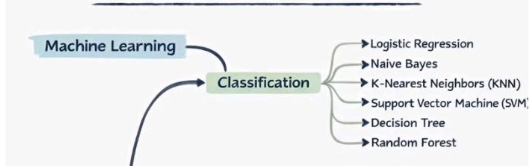

Regression is used when the target variable is a continuous numerical value. Examples include predicting a house price, a student’s expected salary package, or tomorrow’s temperature. The output is a real number rather than a category.

Common regression algorithms include:
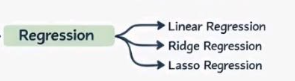

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/student_cleaned.csv")
df["Placement_Status"] = df["Placement_Status"].str.title()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# Convert target to 0/1
df["Placement_Status"] = (
    df["Placement_Status"]
    .astype(str)
    .str.strip()
    .map({"Placed": 1, "Not Placed": 0})
)

# Select a few features
X = df[["CGPA", "Attendance", "Study_Hours"]]
y = df["Placement_Status"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = LogisticRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8061224489795918


In [ ]:
new_student = [[8.5, 90, 4]]  # [CGPA, Attendance, Study_Hours]
prediction = model.predict(new_student)[0]

if prediction == 1:
    print("Predicted: Placed")
else:
    print("Predicted: Not Placed")

Predicted: Placed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
new_student = [[6.2, 90, 3]]  # [CGPA, Attendance, Study_Hours]
prediction = model.predict(new_student)[0]

if prediction == 1:
    print("Predicted: Placed")
else:
    print("Predicted: Not Placed")

Predicted: Not Placed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
new_student = [[5, 40, 4]]  # [CGPA, Attendance, Study_Hours]
prediction = model.predict(new_student)[0]

if prediction == 1:
    print("Predicted: Placed")
else:
    print("Predicted: Not Placed")

Predicted: Not Placed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
new_student = [[8.0, 85, 4]]  # [CGPA, Attendance, Study_Hours]
prediction = model.predict(new_student)[0]

if prediction == 1:
    print("Predicted: Placed")
else:
    print("Predicted: Not Placed")

Predicted: Not Placed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd

df_new = pd.read_csv("/content/drive/MyDrive/Teen_Mental_Health_Dataset.csv")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X = df_new[["daily_social_media_hours","sleep_hours","academic_performance","stress_level",
    "anxiety_level",
    "addiction_level"]]
y = df_new["depression_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model1 = LogisticRegression(max_iter=1000)
model1.fit(X_train, y_train)

y_pred = model1.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9916666666666667


In [ ]:
social_media = float(input("Daily social media hours: "))
sleep = float(input("Sleep hours: "))
academic = float(input("Academic performance: "))
stress = float(input("Stress level: "))
anxiety = float(input("Anxiety level: "))
addiction = float(input("Addiction level: "))

new_data = [[social_media, sleep, academic,
             stress, anxiety, addiction]]

prediction = model1.predict(new_data)[0]
probability = model1.predict_proba(new_data)[0][1]

if prediction == 1:
    print(f"Predicted: Depressed (probability = {probability:.2f})")
else:
    print(f"Predicted: Not Depressed (probability = {1-probability:.2f})")

Daily social media hours: 3.2
Sleep hours: 6
Academic performance: 4
Stress level: 7
Anxiety level: 6
Addiction level: 5
Predicted: Not Depressed (probability = 1.00)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
